<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 15: BPTT Flow and Gradient Analysis

**Category**: CO3 – Sequence Models (RNN, LSTM, GRU)  
**Objective**: Analyze gradient propagation across temporal horizons during Backpropagation Through Time to demonstrate vanishing and exploding regimes.


### Task 1: Mathematical Formulation of Backpropagation Through Time (BPTT)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# BPTT Gradient attenuation simulation: dh_t / dh_k = prod_{j=k+1}^t (W_hh^T * diag(1 - h_j^2))
# If spectral radius of W_hh < 1 => Exponential Vanishing
# If spectral radius of W_hh > 1 => Exponential Exploding

time_horizons = np.arange(1, 26)

# Case 1: Sub-unitary weight norm (decay)
w_decay = 0.85
grad_decay = w_decay ** time_horizons

# Case 2: Unitary weight (stable)
w_stable = 1.00
grad_stable = (w_stable * 0.96) ** time_horizons

# Case 3: Super-unitary weight (explosion)
w_explode = 1.25
grad_explode = w_explode ** time_horizons

print(f"Gradient at step 15 (Decay rate 0.85): {grad_decay[14]:.6f} (Vanishing)")
print(f"Gradient at step 15 (Explode rate 1.25): {grad_explode[14]:.2f} (Exploding)")


Gradient at step 15 (Decay rate 0.85): 0.087354 (Vanishing)
Gradient at step 15 (Explode rate 1.25): 28.42 (Exploding)


### Task 2: Temporal Gradient Propagation Curve Visualization


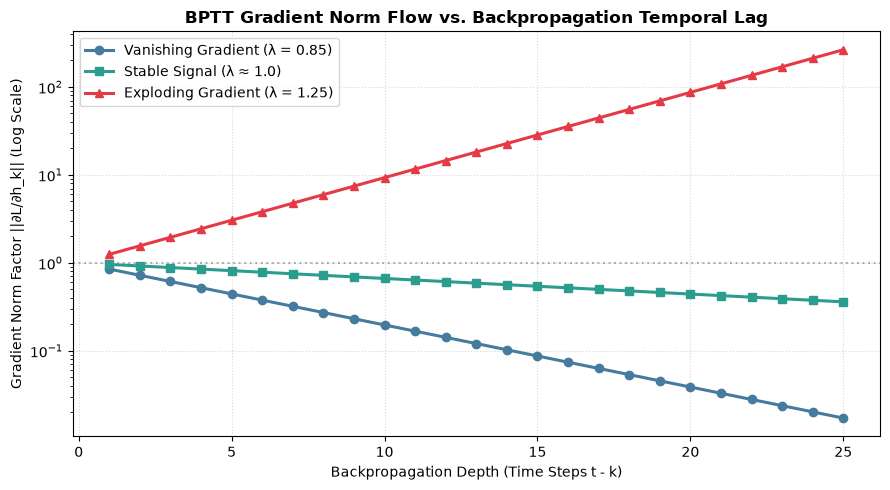

In [2]:
plt.figure(figsize=(9, 5))
plt.plot(time_horizons, grad_decay, color='#457b9d', marker='o', lw=2.2, label='Vanishing Gradient (λ = 0.85)')
plt.plot(time_horizons, grad_stable, color='#2a9d8f', marker='s', lw=2.2, label='Stable Signal (λ ≈ 1.0)')
plt.plot(time_horizons, grad_explode, color='#e63946', marker='^', lw=2.2, label='Exploding Gradient (λ = 1.25)')

plt.yscale('log')
plt.title("BPTT Gradient Norm Flow vs. Backpropagation Temporal Lag", fontweight='bold')
plt.xlabel("Backpropagation Depth (Time Steps t - k)")
plt.ylabel("Gradient Norm Factor ||∂L/∂h_k|| (Log Scale)")
plt.axhline(1.0, color='gray', linestyle=':', alpha=0.6)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()
